# Armed Bandits

This notebook explores Armed Bandits RL algorithm. It basically comes down to picking the action with the highest average so far.

Given $n$ actions $A_i$ that can be taken. Each action follows a particular distribution $A_i ~ D$. The objective is to find a policy maximizes the reward at each particular point in time, as quickly as possible.

## Setup

We start by defining $n$ actions and their distributions.

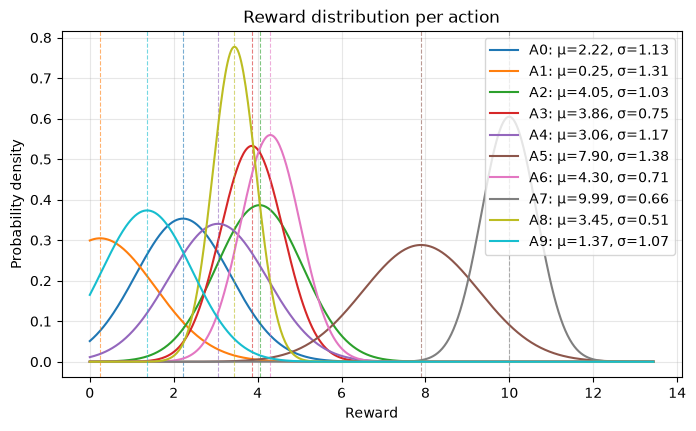

In [42]:
import matplotlib.pyplot as plt
import numpy as np

num_actions = 10
rng = np.random.default_rng()

def create_actions(num_actions, mean_range=(0, 10), sigma_range=(0.5, 1.5)):
    """Create num_actions Gaussian actions as a list of (mean, sigma) tuples."""
    means = rng.uniform(*mean_range, size=num_actions)
    sigmas = rng.uniform(*sigma_range, size=num_actions)
    return list(zip(means, sigmas))


def call_action(par):
    """Take the action with parameters par = (mean, sigma) and return a sampled reward."""
    mean, sigma = par
    return float(rng.normal(mean, sigma))


def gaussian_pdf(x, mean, sigma):
    return np.exp(-0.5 * ((x - mean) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))


actions = create_actions(num_actions)
lo = 0
hi = max(m + 4 * s for m, s in actions)
x = np.linspace(lo, hi, 500)

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (mean, sigma) in enumerate(actions):
    line, = ax.plot(x, gaussian_pdf(x, mean, sigma), label=f"A{i}: μ={mean:.2f}, σ={sigma:.2f}")
    ax.axvline(mean, color=line.get_color(), linestyle="--", linewidth=0.8, alpha=0.6)

ax.set_xlabel("Reward")
ax.set_ylabel("Probability density")
ax.set_title("Reward distribution per action")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

## Reward Tables

Now that we have the actions set up, we want to store the progressive reward for each action.
Essentially, we just track the mean of each action:

$$
    Q_t(a) = \frac{1}{t-1}\sum_{i=1}^{t-1} R_i.
$$

Hence we must track of the number of time steps $t$ for each action, and its rewards. 
A recursive expression allows us to update $Q$ on the fly instead of recomputing it every time:

$$
    Q_t(a) = Q_{t-1} + \frac{1}{t-1}(R_t - Q_{t-1}).
$$

Hence let us track the latest value $Q$ and number of steps $t$ for each action.

## The Algorithm

Finally, the algorithm comes down to the following steps:
- Pick the highest-scoring action with probability $1 - \varepsilon$, otherwise random.
- Perform the action and obtain a reward $R_t$.
- Update the $Q$ value for this action and increment time.

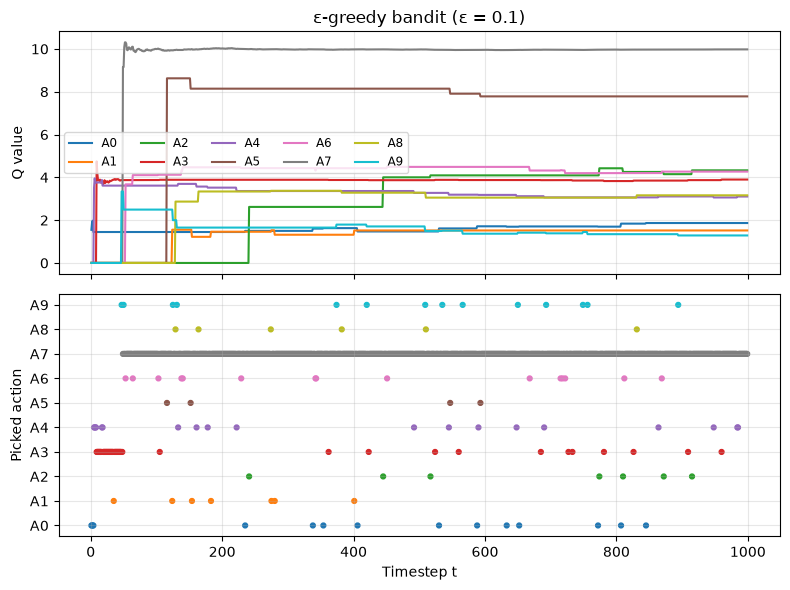

In [ ]:
num_timesteps = 50
epsilon = 0.1

iteration_range = list(range(1, num_timesteps))
action_q_values = np.zeros(num_actions)
action_t_count = np.ones(num_actions)
action_history = []
action_q_history = []
total_reward_history = [ 0 ]

for i in iteration_range:
    # Pick optimal or random action.
    ai = 0
    if rng.uniform() < epsilon:
        ai = rng.integers(num_actions)
    else:
        ai = np.argmax(action_q_values)

    # Perform action.
    reward = call_action(actions[ai])
    total_reward_history.append(total_reward_history[-1] + reward)
    action_history.append(ai)

    # Update Q values.
    q,t = action_q_values[ai], action_t_count[ai]
    action_q_values[ai] = q + 1.0 / t * (reward - q)
    action_t_count[ai] += 1
    action_q_history.append(action_q_values.copy())

fig, (ax_q, ax_action) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# Plot 1: Q value of each action over time, same colors/order as the plot below.
q_history = np.array(action_q_history)  # shape (timesteps, num_actions)
for a in range(num_actions):
    ax_q.plot(iteration_range, q_history[:, a], color=f"C{a}", label=f"A{a}")
ax_q.set_ylabel("Q value")
ax_q.set_title(f"ε-greedy bandit (ε = {epsilon})")
ax_q.legend(ncol=5, fontsize="small")
ax_q.grid(True, alpha=0.3)

# Plot 2: picked action over time, colored to match the distribution plot.
ax_action.scatter(iteration_range, action_history, c=[f"C{a}" for a in action_history], s=12)
ax_action.set_yticks(range(num_actions), [f"A{a}" for a in range(num_actions)])
ax_action.set_ylabel("Picked action")
ax_action.set_xlabel("Timestep t")
ax_action.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()